In [1]:
print("hello")

hello


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [6]:
#load the dataset into this notebook
df= pd.read_csv("../datasets/product_reviews.csv")
df.head()
df.tail()

,parent_asin,text,rating,timestamp
2995,B01G8JO5F2,Don’t waste your money. The range in this thi...,1.0,1512332703282
2996,B01G8JO5F2,"These headphones are a very good product, and ...",4.0,1525297355523
2997,B01G8JO5F2,So far very good headphones. Pairing was flawl...,5.0,1488757466000
2998,B01G8JO5F2,"Secure fit, good sound and battery life.",5.0,1546382611490
2999,B01G8JO5F2,"It break too fast, but great sound for the pri...",3.0,1549650081837


In [5]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   parent_asin  3000 non-null   str    
 1   text         2998 non-null   str    
 2   rating       3000 non-null   float64
 3   timestamp    3000 non-null   int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 755.7 KB


,rating,timestamp
count,3000.000000,3.000000e+03
mean,3.849333,1.566279e+12
std,1.497569,3.182984e+10
min,1.000000,1.471484e+12
25%,3.000000,1.551105e+12
50%,5.000000,1.563627e+12
75%,5.000000,1.577771e+12
max,5.000000,1.677797e+12


In [7]:
# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 3000
Columns: 4


In [8]:
df.columns

Index(['parent_asin', 'text', 'rating', 'timestamp'], dtype='str')

In [9]:
# Statistical summary
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
parent_asin,3000,1,B01G8JO5F2,3000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,2998,2956,Good,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,3000.0,NaN,NaN,NaN,3.849333,1.497569,1.0,3.0,5.0,5.0,5.0
timestamp,3000.0,NaN,NaN,NaN,1566279093071.065918,31829844702.288227,1471484440000.0,1551104728402.5,1563626570285.5,1577770902274.0,1677797084506.0


In [10]:
df.isnull().sum()

parent_asin    0
text           2
rating         0
timestamp      0
dtype: int64

In [12]:
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

missing_percentage

parent_asin    0.00
text           0.07
rating         0.00
timestamp      0.00
dtype: float64

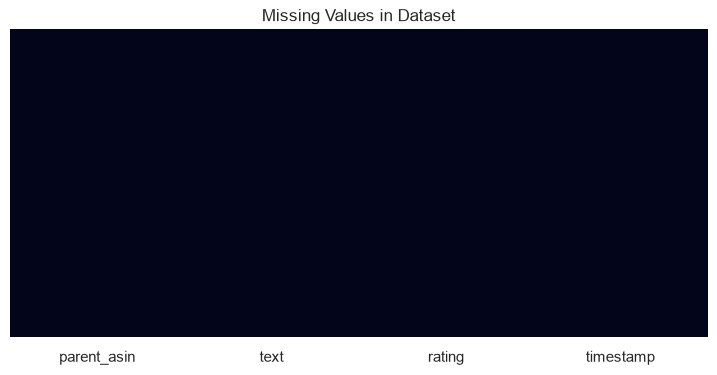

In [13]:
#visualising missing values on the graph
plt.figure(figsize=(9, 4))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Dataset")
plt.show()

In [14]:
#checking duplicate values
print(
    "Exact duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate review texts:",
    df["text"].duplicated().sum()
)

Exact duplicate rows: 2
Duplicate review texts: 43


In [15]:
#understanding how cusotomers are rating this particcular product
print(df["rating"].value_counts().sort_index())

rating
1.0     449
2.0     233
3.0     230
4.0     497
5.0    1591
Name: count, dtype: int64


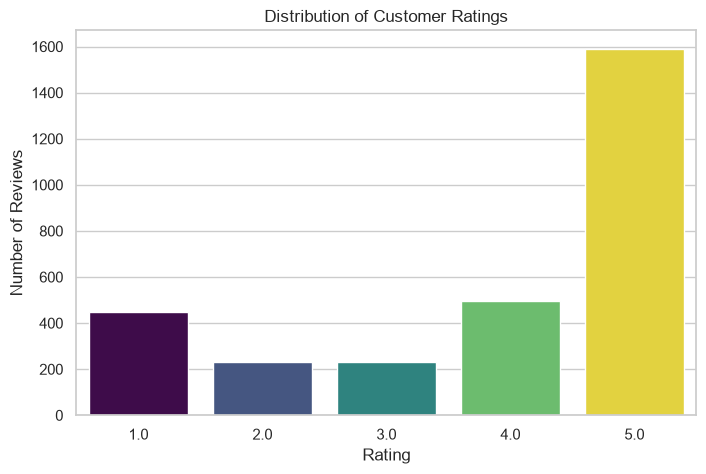

In [16]:
#plotting this data
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating",
    hue="rating",
    order=sorted(df["rating"].dropna().unique()),
    palette="viridis",
    legend=False
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

In [17]:
#calculating percentage
rating_percentage = (
    df["rating"].value_counts(normalize=True)
    .sort_index() * 100
)

rating_percentage

rating
1.0    14.966667
2.0     7.766667
3.0     7.666667
4.0    16.566667
5.0    53.033333
Name: proportion, dtype: float64

In [18]:
#understanding how the rewviews are written 
df["review_length"] = df["text"].fillna("").str.len()

df["word_count"] = (
    df["text"]
    .fillna("")
    .str.split()
    .str.len()
)

In [22]:
df[["review_length", "word_count"]].describe()

,review_length,word_count
count,3000.000000,3000.000000
mean,215.238333,39.778000
std,323.042064,59.194065
min,0.000000,0.000000
25%,56.000000,10.000000
50%,129.500000,24.000000
75%,275.000000,51.000000
max,9118.000000,1637.000000


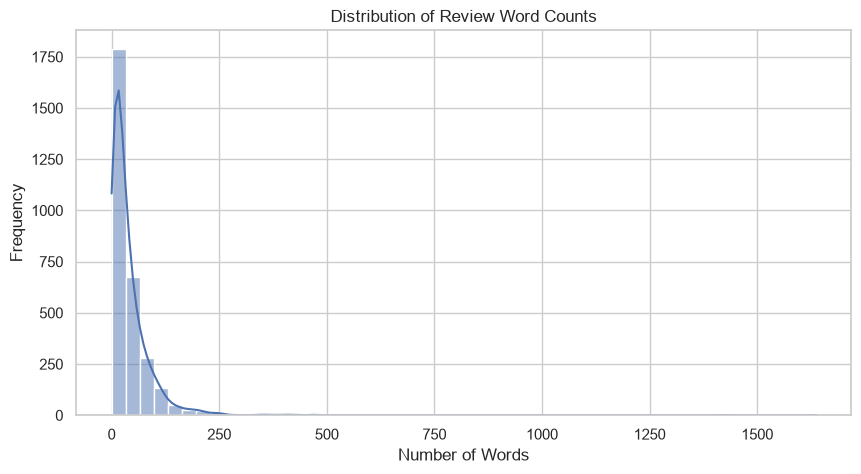

In [23]:
#plotting this data into graph
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=50,
    kde=True
)

plt.title("Distribution of Review Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

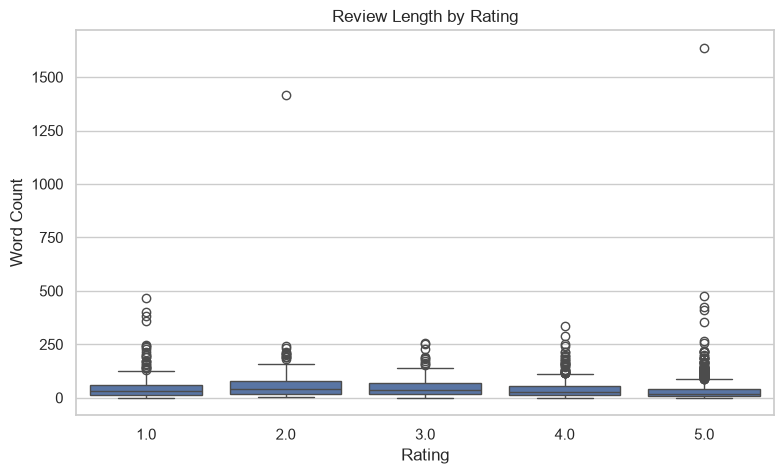

In [24]:
#compareing using the rating part  of the review
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="rating",
    y="word_count"
)

plt.title("Review Length by Rating")
plt.xlabel("Rating")
plt.ylabel("Word Count")

plt.show()

In [25]:
#now reviewing the timestamp part
df["timestamp"].head(10)


0    1523093017534
1    1616158376457
2    1551131667447
3    1520112167959
4    1499306245642
5    1495648182000
6    1547766190821
7    1493721535000
8    1567476111418
9    1574287115544
Name: timestamp, dtype: int64

In [26]:
#this is in the format of unix millisecond that requires 13 digits of integer
#convert this into 3 collumns of year,month,day
df["review_date"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce",
    utc=True
)

df["review_year"] = df["review_date"].dt.year
df["review_month"] = df["review_date"].dt.month

df[["timestamp", "review_date", "review_year"]].head()


,timestamp,review_date,review_year
0,1523093017534,2018-04-07 09:23:37.534+00:00,2018
1,1616158376457,2021-03-19 12:52:56.457+00:00,2021
2,1551131667447,2019-02-25 21:54:27.447+00:00,2019
3,1520112167959,2018-03-03 21:22:47.959+00:00,2018
4,1499306245642,2017-07-06 01:57:25.642+00:00,2017


In [27]:
#checking both the data for earliest as well as latest review
print("Earliest review:", df["review_date"].min())
print("Latest review:", df["review_date"].max())

Earliest review: 2016-08-18 01:40:40+00:00
Latest review: 2023-03-02 22:44:44.506000+00:00


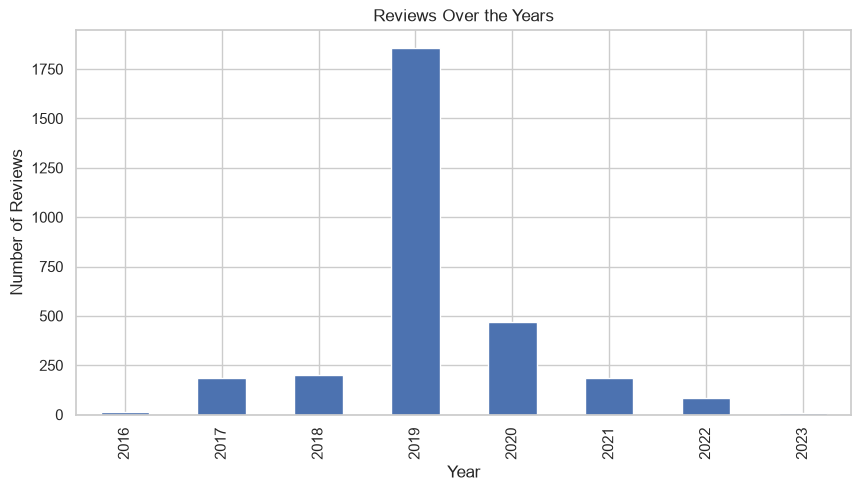

In [28]:
#sorting the yearly review collumns
yearly_reviews = df["review_year"].value_counts().sort_index()
#plotting this into a grap
yearly_reviews.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Reviews Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")

plt.show()

In [29]:
#exploring the actual reviews
pd.set_option("display.max_colwidth", 200)

df[["rating", "text"]].sample(
    min(10, len(df)),
    random_state=42
)

,rating,text
1801,4.0,Hurt ur ears after a while
1190,4.0,If they had been magnetic and announced battery life they would be perfect
1817,5.0,I really like the them they work great!
251,5.0,"I purchased these headphones to replace a pair that had stopped working (would no longer synch up). The previous set was probably over a year old, but honestly I really don't remember exactly whe..."
2505,3.0,Sound randomly cuts out. Followed directions and reconnected pods. Still occasionally cuts out.
1117,3.0,"Decent for what they’re worth, I bought my pair 14months ago and stoped working two days ago. they started acting funny and stopped connecting and just shutting off after you turn them on, even w..."
1411,5.0,"Great headphones, the hooks keep them in my ears even when I'm working out. Also, noice cancelation is great with the supplied foam buds. Some people may be turned off that they still have a cord ..."
2113,5.0,Noise cancelling is very good. I walk on a treadmill and watch TV or movies while working out. No problem hearing. I actually had to turn down the volume. Very good!
408,5.0,They are great
2579,5.0,I bought them to do Jogging and works great.


In [32]:
#exploring  negative reviews
negative_reviews = df[df["rating"] <= 2]

negative_reviews[["rating", "text"]].head(10)

,rating,text
2,1.0,When I buy it for the first it was very nice but now material are not good.
17,1.0,This is a generic product sold under a few different brand names. The fit of these buds in my ear canal is poor for my ears - they will not stay in place no matter which ear tip I use. The sound q...
26,1.0,"I purchased this product back in August, 2017. They've were great for about a month and randomly started having problems maintaining connection with my phone while playing music. It wouldn't disco..."
33,2.0,"Looks like it is a defective piece, the person on the other side cannot hear me and it happen every time I use it. Returning it !"
38,1.0,"I bought these headphones on OCT 7, 2017. All of a sudden, they stopped charging and working! The product is made to work only for 1 year."
41,1.0,"The headphones worked beautifully at first, but then the power button got stuck inside and it was all over."
43,1.0,Girlfriend bought these for me back in May. I use these when I go to the gym and right when I first turned them on I wasn’t impressed with the sound quality. I’ve had cheaper bluetooth headphones ...
44,2.0,"Didnt work well for me. Everytime I tried to sync it to my bluetooth, it would take about 30 minutes. Def not worth it. When it did work, it was a great sound. I found another for 10$ cheaper..."
47,1.0,Terrible Bluetooth connection. Always cuts out. Have to have your phone unobstructed.
60,1.0,Despite being advertised as IPX7 or whatever they are not waterproof.


In [36]:
#exploring some posotove reviews 
positive_reviews=df[df["rating"]>=4]

positive_reviews[["rating","text"]].head(10)

,rating,text
0,5.0,"I love these. They even come with a carry case and several sizes of ear bud inserts. Thank heaven! I get ear pain from most, but the smallest buds fit great. They also have a charger and all of ..."
1,5.0,For the price these are great quality. Bought them for my spouse in 2018 and they still work great! I ended up buying a second pare to give to a sibling.
3,5.0,I am so happy with these!! I have a lot of ear piercings all throughout my ear and so I never know if ear phones will work with that. Especially since these have the clips I was unsure. It doesn’t...
5,5.0,"I had a hard time with these at first until I figured out that you have to hold down the multi-purpose button until a woman's voice says that it is now on, and same thing to turn it off. But they ..."
6,5.0,When I initially purchased the head phones I misread the description and assumed they where fully waterproof headphones that I can use for the pool. I figured because of the great value the qualit...
8,4.0,Very nice sound with this headphones but they do stick out on the side of your head if you are looking for the aesthetics as you are wearing them. I have had several issues with them losing signal...
10,4.0,The sound quality is very good and they easily fit my ears my only problem is the button to turn on and off is so easily accessible that I find myself accidentally shutting them off when I adjust ...
11,5.0,"Great headphones! They are easy to use, hold a lasting charge, and block out all outside noise. Wish I would have bought these sooner"
12,4.0,some connectivity issues with drops could be a faulty pair but sound great for the money
13,5.0,"I loved my pair. It lasted me a year before it stopped working but to be fair I have a rough job and would wear these all day. Speaking of all day, the battery would last the full 8+ hours. To be ..."


In [37]:
#calculating positive negative and nuetral reviews 
def classify_rating(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["rating_category"] = df["rating"].apply(classify_rating)

print(
    df["rating_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

rating_category
Positive    69.60
Negative    22.73
Neutral      7.67
Name: proportion, dtype: float64


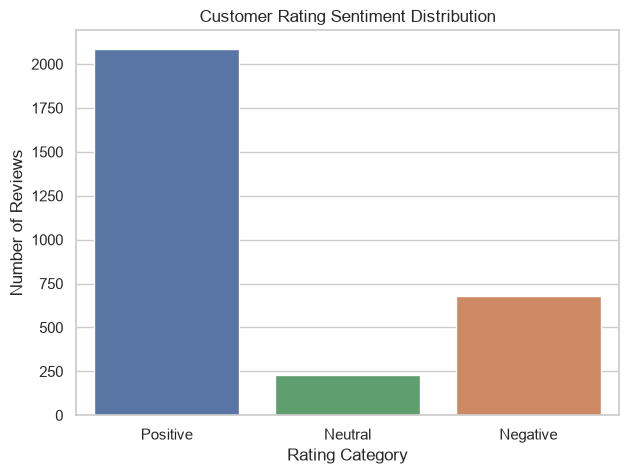

In [38]:
#plotting the above data
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="rating_category",
    order=["Positive", "Neutral", "Negative"],
    hue="rating_category",
    legend=False
)

plt.title("Customer Rating Sentiment Distribution")
plt.xlabel("Rating Category")
plt.ylabel("Number of Reviews")

plt.show()

# EDA Conclusions

1. Total number of reviews:3000

2. Missing values:2 in ["text"] column 

3. Duplicate reviews:Exact duplicate rows: 2
                     Duplicate review texts: 43

4. Most common rating:
Positive    69.60
Negative    22.73
Neutral      7.67

5. Average review word count: around 39

6. Distribution of positive and negative ratings:

7. Review date range:2016-2022 peaked in 2019

8. Important observations about customer feedback: most people did not like the bluetooth connection , 
issues regarding the multipurposre button (there was a real learning curve for that ) , 
value for money in accordance with the sound quality 

9. Data quality issues that need preprocessing: 2 missing values in the review ssection , 
and also there are duplicate values 


In [39]:
#exploring the duplicate part 
duplicate_reviews = df[
    df["text"].duplicated(keep=False)
].sort_values("text")

duplicate_reviews[["rating", "text"]].head(20)

,rating,text
2860,1.0,Amazing sound! But...<br />The mic is TERRIBLE!! You can't be heard.<br />Sending these back
2870,1.0,Amazing sound! But...<br />The mic is TERRIBLE!! You can't be heard.<br />Sending these back
830,5.0,Awesome
868,5.0,Awesome
2693,5.0,Awesome!
2893,5.0,Awesome!
1035,2.0,Cheap quality
1221,3.0,Cheap quality
205,5.0,Good
467,5.0,Good


In [43]:
#checking the missing review text part 
df[df["text"].isna()]

,parent_asin,text,rating,timestamp,review_length,word_count,review_date,review_year,review_month,rating_category
1113,B01G8JO5F2,NaN,5.0,1624190618062,0,0,2021-06-20 12:03:38.062+00:00,2021,6,Positive
1583,B01G8JO5F2,NaN,5.0,1565182233463,0,0,2019-08-07 12:50:33.463+00:00,2019,8,Positive


In [44]:
df.columns

Index(['parent_asin', 'text', 'rating', 'timestamp', 'review_length',
       'word_count', 'review_date', 'review_year', 'review_month',
       'rating_category'],
      dtype='str')

In [45]:
print(
    "Empty strings:",
    df["text"].fillna("").str.strip().eq("").sum()
)

Empty strings: 2


In [47]:
df.describe()

,rating,timestamp,review_length,word_count,review_year,review_month
count,3000.000000,3.000000e+03,3000.000000,3000.000000,3000.000000,3000.000000
mean,3.849333,1.566279e+12,215.238333,39.778000,2019.173333,6.046333
std,1.497569,3.182984e+10,323.042064,59.194065,1.006128,3.589589
min,1.000000,1.471484e+12,0.000000,0.000000,2016.000000,1.000000
25%,3.000000,1.551105e+12,56.000000,10.000000,2019.000000,3.000000
50%,5.000000,1.563627e+12,129.500000,24.000000,2019.000000,6.000000
75%,5.000000,1.577771e+12,275.000000,51.000000,2019.000000,9.000000
max,5.000000,1.677797e+12,9118.000000,1637.000000,2023.000000,12.000000


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   parent_asin      3000 non-null   str                
 1   text             2998 non-null   str                
 2   rating           3000 non-null   float64            
 3   timestamp        3000 non-null   int64              
 4   review_length    3000 non-null   int64              
 5   word_count       3000 non-null   int64              
 6   review_date      3000 non-null   datetime64[us, UTC]
 7   review_year      3000 non-null   int32              
 8   review_month     3000 non-null   int32              
 9   rating_category  3000 non-null   str                
dtypes: datetime64[us, UTC](1), float64(1), int32(2), int64(3), str(3)
memory usage: 896.1 KB


In [50]:
df.head(4)

,parent_asin,text,rating,timestamp,review_length,word_count,review_date,review_year,review_month,rating_category
0,B01G8JO5F2,"I love these. They even come with a carry case and several sizes of ear bud inserts. Thank heaven! I get ear pain from most, but the smallest buds fit great. They also have a charger and all of ...",5.0,1523093017534,469,94,2018-04-07 09:23:37.534+00:00,2018,4,Positive
1,B01G8JO5F2,For the price these are great quality. Bought them for my spouse in 2018 and they still work great! I ended up buying a second pare to give to a sibling.,5.0,1616158376457,153,31,2021-03-19 12:52:56.457+00:00,2021,3,Positive
2,B01G8JO5F2,When I buy it for the first it was very nice but now material are not good.,1.0,1551131667447,75,17,2019-02-25 21:54:27.447+00:00,2019,2,Negative
3,B01G8JO5F2,I am so happy with these!! I have a lot of ear piercings all throughout my ear and so I never know if ear phones will work with that. Especially since these have the clips I was unsure. It doesn’t...,5.0,1520112167959,302,58,2018-03-03 21:22:47.959+00:00,2018,3,Positive


In [51]:
df.tail(4)

,parent_asin,text,rating,timestamp,review_length,word_count,review_date,review_year,review_month,rating_category
2996,B01G8JO5F2,"These headphones are a very good product, and at a great price. The sound quality is good and the battery life is great. Great for work or working out.",4.0,1525297355523,151,29,2018-05-02 21:42:35.523+00:00,2018,5,Positive
2997,B01G8JO5F2,So far very good headphones. Pairing was flawless. Sound quality is very good.,5.0,1488757466000,78,13,2017-03-05 23:44:26.000+00:00,2017,3,Positive
2998,B01G8JO5F2,"Secure fit, good sound and battery life.",5.0,1546382611490,40,7,2019-01-01 22:43:31.490+00:00,2019,1,Positive
2999,B01G8JO5F2,"It break too fast, but great sound for the price better then some premium headphone",3.0,1549650081837,83,15,2019-02-08 18:21:21.837+00:00,2019,2,Neutral


# checkin the  cleaned dataset 

In [52]:
data=pd.read_csv("../datasets/cleaned_reviews.csv")
data.head()

,parent_asin,text,rating,timestamp,cleaned_text,word_count
0,B01G8JO5F2,"I love these. They even come with a carry case and several sizes of ear bud inserts. Thank heaven! I get ear pain from most, but the smallest buds fit great. They also have a charger and all of ...",5.0,1523093017534,"I love these. They even come with a carry case and several sizes of ear bud inserts. Thank heaven! I get ear pain from most, but the smallest buds fit great. They also have a charger and all of it...",94
1,B01G8JO5F2,For the price these are great quality. Bought them for my spouse in 2018 and they still work great! I ended up buying a second pare to give to a sibling.,5.0,1616158376457,For the price these are great quality. Bought them for my spouse in 2018 and they still work great! I ended up buying a second pare to give to a sibling.,31
2,B01G8JO5F2,When I buy it for the first it was very nice but now material are not good.,1.0,1551131667447,When I buy it for the first it was very nice but now material are not good.,17
3,B01G8JO5F2,I am so happy with these!! I have a lot of ear piercings all throughout my ear and so I never know if ear phones will work with that. Especially since these have the clips I was unsure. It doesn’t...,5.0,1520112167959,I am so happy with these!! I have a lot of ear piercings all throughout my ear and so I never know if ear phones will work with that. Especially since these have the clips I was unsure. It doesn’t...,58
4,B01G8JO5F2,"These are great for around the house and casual uses but when I wear them running there's a lot of wind noise. Not good for running, for me. Wind noise is annoying & distracting.",3.0,1499306245642,"These are great for around the house and casual uses but when I wear them running there's a lot of wind noise. Not good for running, for me. Wind noise is annoying & distracting.",34


In [56]:
data.shape

(2996, 6)

In [60]:
data.isnull().sum()

parent_asin     0
text            0
rating          0
timestamp       0
cleaned_text    0
word_count      0
dtype: int64

In [61]:
print("Exact duplicate rows:", data.duplicated().sum())

print(
    "Duplicate cleaned texts:",
    data["cleaned_text"].duplicated().sum()
)

Exact duplicate rows: 0
Duplicate cleaned texts: 40


In [62]:
#checking review length
data["word_count"].describe()

count    2996.000000
mean       39.706609
std        58.839918
min         1.000000
25%        10.000000
50%        24.000000
75%        51.000000
max      1631.000000
Name: word_count, dtype: float64

In [63]:
data[["text", "cleaned_text"]].sample(
    10,
    random_state=42
)

,text,cleaned_text
1375,"Excellent headphones, I was expecting less, but I really crush on it. Excellent quality. Perfect fit over the ears, non slippery even when sweating.""","Excellent headphones, I was expecting less, but I really crush on it. Excellent quality. Perfect fit over the ears, non slippery even when sweating."""
932,The only reason that this didn't get 5 stars is because the ear loops don't fit me (and the package didn't come with any adjustable sizes) BUT the earbuds themselves actually fit pretty snug in my...,The only reason that this didn't get 5 stars is because the ear loops don't fit me (and the package didn't come with any adjustable sizes) BUT the earbuds themselves actually fit pretty snug in my...
144,I purchased a activbuds s-250 2.5 years ago. I've run multiple half and full marathons with them and loved them. When they got stepped on I researched and purchased activbuds A1. They have the sa...,I purchased a activbuds s-250 2.5 years ago. I've run multiple half and full marathons with them and loved them. When they got stepped on I researched and purchased activbuds A1. They have the sam...
2555,much cheaper material than my prior one.,much cheaper material than my prior one.
51,My grandson they were perfect for him,My grandson they were perfect for him
414,"I'm indicicive w this kind of stuff so I had to finally just buy a pair, I'm stoked on these. Good sound, $40, what else you want for the price","I'm indicicive w this kind of stuff so I had to finally just buy a pair, I'm stoked on these. Good sound, $40, what else you want for the price"
2303,"Had a pair of earbuds that only stayed charged for 2 hours, these have lasted over 9, LOVE them!","Had a pair of earbuds that only stayed charged for 2 hours, these have lasted over 9, LOVE them!"
266,"Ear hook doesn’t provide much support; nonetheless, when both earphones are tightly in place then the sound quality is great.","Ear hook doesn’t provide much support; nonetheless, when both earphones are tightly in place then the sound quality is great."
2702,"I like so much, really good","I like so much, really good"
2421,Excelente quality excede my expectations.,Excelente quality excede my expectations.


In [64]:
#checking the embedding 

embeddings = np.load("../artifacts/review_embeddings.npy")

print("Shape:", embeddings.shape)
print("Data type:", embeddings.dtype)

Shape: (2996, 384)
Data type: float32


In [65]:

# Load clustered reviews
df = pd.read_csv("../artifacts/clustered_reviews.csv")

print("Dataset shape:", df.shape)

# Show cluster sizes
print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index())

Dataset shape: (2996, 7)

Cluster sizes:
cluster
-1     705
 0      48
 1      60
 2     103
 3      44
 4     144
 5      71
 6     165
 7      39
 8      36
 9      41
 10     42
 11    314
 12     30
 13     39
 14     35
 15    124
 16     77
 17    120
 18     56
 19     39
 20    160
 21     65
 22     51
 23    221
 24     96
 25     71
Name: count, dtype: int64


In [67]:
df.head()

,parent_asin,text,rating,timestamp,cleaned_text,word_count,cluster
0,B01G8JO5F2,"I love these. They even come with a carry case and several sizes of ear bud inserts. Thank heaven! I get ear pain from most, but the smallest buds fit great. They also have a charger and all of ...",5.0,1523093017534,"I love these. They even come with a carry case and several sizes of ear bud inserts. Thank heaven! I get ear pain from most, but the smallest buds fit great. They also have a charger and all of it...",94,-1
1,B01G8JO5F2,For the price these are great quality. Bought them for my spouse in 2018 and they still work great! I ended up buying a second pare to give to a sibling.,5.0,1616158376457,For the price these are great quality. Bought them for my spouse in 2018 and they still work great! I ended up buying a second pare to give to a sibling.,31,6
2,B01G8JO5F2,When I buy it for the first it was very nice but now material are not good.,1.0,1551131667447,When I buy it for the first it was very nice but now material are not good.,17,4
3,B01G8JO5F2,I am so happy with these!! I have a lot of ear piercings all throughout my ear and so I never know if ear phones will work with that. Especially since these have the clips I was unsure. It doesn’t...,5.0,1520112167959,I am so happy with these!! I have a lot of ear piercings all throughout my ear and so I never know if ear phones will work with that. Especially since these have the clips I was unsure. It doesn’t...,58,23
4,B01G8JO5F2,"These are great for around the house and casual uses but when I wear them running there's a lot of wind noise. Not good for running, for me. Wind noise is annoying & distracting.",3.0,1499306245642,"These are great for around the house and casual uses but when I wear them running there's a lot of wind noise. Not good for running, for me. Wind noise is annoying & distracting.",34,25


In [68]:
df.columns


Index(['parent_asin', 'text', 'rating', 'timestamp', 'cleaned_text',
       'word_count', 'cluster'],
      dtype='str')

In [69]:
print("Columns:", [repr(col) for col in df.columns])

print("\nDataFrame shape:", df.shape)

print("\nCluster column sample:")
print(df["cluster"].head())

Columns: ["'parent_asin'", "'text'", "'rating'", "'timestamp'", "'cleaned_text'", "'word_count'", "'cluster'"]

DataFrame shape: (2996, 7)

Cluster column sample:
0    -1
1     6
2     4
3    23
4    25
Name: cluster, dtype: int64


In [71]:

# Load clustered dataset
df = pd.read_csv("../artifacts/clustered_reviews.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Remove noise reviews (-1)
clustered = df[df["cluster"] != -1].copy()

# Create an empty list to store samples
sample_list = []

# Select 5 reviews from every cluster
for cluster_id, group in clustered.groupby("cluster"):

    selected = group.sample(
        n=min(5, len(group)),
        random_state=42
    )

    sample_list.append(selected)

# Combine samples into one DataFrame
samples = pd.concat(sample_list, ignore_index=True)

print("Total sample reviews:", len(samples))
print("Total clusters:", samples["cluster"].nunique())

Total sample reviews: 130
Total clusters: 26


In [72]:
for cluster_id in sorted(samples["cluster"].unique()):

    print("\n" + "=" * 80)
    print(f"CLUSTER {cluster_id}")
    print("=" * 80)

    cluster_reviews = samples[
        samples["cluster"] == cluster_id
    ]

    for _, row in cluster_reviews.iterrows():
        print("\nRating:", row["rating"])
        print("Review:", row["cleaned_text"])


CLUSTER 0

Rating: 5.0
Review: Buena compra

Rating: 5.0
Review: El articulo correspondía con la descripción, muy buen producto llego a tiempo. Es eñ tercero que compro para regalo.

Rating: 5.0
Review: Excelente más de un 100 padrisimo. Buen sonido

Rating: 5.0
Review: Me encanta

Rating: 5.0
Review: Calidad buena

CLUSTER 1

Rating: 5.0
Review: I like the sound. Use when exercising. Like that I can adjust the earpiece around my ear. But, as usual, I have difficulty keeping an earbud in my ear. However, Senso fits better than any other brand.

Rating: 2.0
Review: I don't write a lot of reviews. I really expected a lot more from these earphones because of high ratings on Amazon. It's obvious that $29 earphones can't deliver audio quality as good as a set of $300 from Sony. Unfortunately I can only compare SENSO's audio quality to earphones sold at a Dollar Store or the earphones given away for free to airline passengers. Senso's mid-range is muffled, high range is almost non-existent 

# as there were other languages of review we have to delete them and focusing just on english reviews for better understanding 

In [73]:

df = pd.read_csv("../artifacts/clustered_reviews.csv")

print("Total reviews:", len(df))
print("Total clusters:", df[df["cluster"] != -1]["cluster"].nunique())

# Exclude noise for now
clustered = df[df["cluster"] != -1].copy()

# Select 8 sample reviews from every cluster
sample_list = []

for cluster_id, group in clustered.groupby("cluster"):
    selected = group.sample(
        n=min(8, len(group)),
        random_state=42
    )
    sample_list.append(selected)

samples = pd.concat(sample_list, ignore_index=True)

# Display samples cluster by cluster
for cluster_id in sorted(samples["cluster"].unique()):

    print("\n" + "=" * 90)
    print(f"CLUSTER {cluster_id}")
    print("=" * 90)

    cluster_reviews = samples[samples["cluster"] == cluster_id]

    for _, row in cluster_reviews.iterrows():
        print("\nRating:", row["rating"])
        print("Review:", row["cleaned_text"])

Total reviews: 2755
Total clusters: 22

CLUSTER 0

Rating: 4.0
Review: This is my 3rd set of Senso Bluetooth headphones. The first set lasted a year until I accidentally ripped off one of the ear pieces. It was an earlier version with the non-adjustable ear hooks which I liked. The mic feature never worked for that set and neither did the music control other than play/pause. I also noticed occasional skipping when my phone was in my pocket. Otherwise I was very happy with the product. The second set I got was more or less the same. I actually DO NOT LIKE the adjustable ear hooks. I take them in and out regularly when talking to people directly and then find I have to take time to readjust them in my ear constantly as the hook doesn't seem to hold its shape very well. I got the new model ones to see if they fixed the ear hook annoyance. It does seem a little better though it might be because they are brand new. It does seem they have fixed the skipping issue. So for the price they are g